# Machine-Learning-Workflow: RGDPO Growth Std Prediction

Dieses Notebook arbeitet die Punkte aus den Folien Schritt für Schritt ab.  
**Ziel:** Vorhersage von `rgdpo_growth_std`, also der Standardabweichung des RGDPO-Wachstums, auf Basis wirtschaftlicher und entwicklungsbezogener Länderindikatoren.

**Datensatz:** `merged.csv`  
**Modelltyp:** Regression, da die Zielvariable numerisch-kontinuierlich ist.

## 0. Setup und Daten laden

Zuerst werden Bibliotheken geladen, der Datensatz eingelesen und Datentypen bereinigt. Die Spalte `Average_annual_HDI_growth_2010-2023` ist im CSV als Text gespeichert und wird in numerisch umgewandelt.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

from sklearn import __version__ as sklearn_version
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge, SGDRegressor
from sklearn.metrics import mean_absolute_error, r2_score
try:
    from sklearn.metrics import root_mean_squared_error
except ImportError:
    from sklearn.metrics import mean_squared_error
    def root_mean_squared_error(y_true, y_pred):
        return mean_squared_error(y_true, y_pred, squared=False)
from sklearn.model_selection import RepeatedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

RANDOM_STATE = 42

candidate_paths = [
    Path("merged.csv")
]
DATA_PATH = next((p for p in candidate_paths if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        "Die Datei merged(4).csv oder merged.csv wurde nicht gefunden. "
        "Bitte lege sie in denselben Ordner wie dieses Notebook oder nach /mnt/data."
    )

print(f"scikit-learn Version: {sklearn_version}")
print(f"Geladene Datei: {DATA_PATH}")

df_raw = pd.read_csv(DATA_PATH)
display(df_raw.head())
print(f"Shape: {df_raw.shape[0]} Zeilen, {df_raw.shape[1]} Spalten")


scikit-learn Version: 1.7.2
Geladene Datei: merged.csv


,country,efotw_summary,efotw_standard_deviation_of_the_5_efw_areas,efotw_world_bank_current_income_classification,hdi_rank,Average_annual_HDI_growth_2010-2023,rgdpo,rgdpo_growth_std,life_evaluation_(3-year_average)
0,Albania,7.5842,1.4939,2.9286,71.0000,0.4003629980676049,"37,933.7257",0.0417,5.0022
1,Algeria,4.6652,1.4735,2.7857,96.0000,0.4686985271329158,"606,469.8438",0.0432,5.4029
2,Angola,4.8542,1.5456,2.3571,148.0000,1.1928326359882835,"238,042.9431",0.0941,4.2093
3,Argentina,5.1335,1.0496,3.1429,47.0000,0.1892327606794364,"1,074,120.1473",0.0620,6.2653
4,Armenia,7.3145,1.4046,2.5000,69.0000,0.6343331865654722,"42,472.2372",0.0718,4.7426


Shape: 135 Zeilen, 9 Spalten


In [2]:
target_col = "rgdpo_growth_std"
id_cols = ["country"]

# Kopie für Modellierung erzeugen
df = df_raw.copy()

# Textspalte in numerisch umwandeln, falls nötig
df["Average_annual_HDI_growth_2010-2023"] = pd.to_numeric(
    df["Average_annual_HDI_growth_2010-2023"], errors="coerce"
)

# Zeilen ohne Zielvariable entfernen; Feature-Missings werden später per Pipeline imputiert.
df = df.dropna(subset=[target_col]).reset_index(drop=True)

feature_cols = [c for c in df.columns if c not in id_cols + [target_col]]
X = df[feature_cols].copy()
y = df[target_col].copy()

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = [c for c in X.columns if c not in numeric_features]

print("Zielvariable:", target_col)
print("Identifier ausgeschlossen:", id_cols)
print("Features:", feature_cols)
print("Numerische Features:", numeric_features)
print("Kategorische Features:", categorical_features if categorical_features else "keine")
print("Hinweis: `life_evaluation_(3-year_average)` wird nun als Feature genutzt, nicht als Zielvariable.")

summary = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_values": df.isna().sum(),
    "missing_%": (df.isna().mean() * 100).round(2),
    "n_unique": df.nunique(),
})
display(summary)
display(df.describe(include="all").T)

Zielvariable: rgdpo_growth_std
Identifier ausgeschlossen: ['country']
Features: ['efotw_summary', 'efotw_standard_deviation_of_the_5_efw_areas', 'efotw_world_bank_current_income_classification', 'hdi_rank', 'Average_annual_HDI_growth_2010-2023', 'rgdpo', 'life_evaluation_(3-year_average)']
Numerische Features: ['efotw_summary', 'efotw_standard_deviation_of_the_5_efw_areas', 'efotw_world_bank_current_income_classification', 'hdi_rank', 'Average_annual_HDI_growth_2010-2023', 'rgdpo', 'life_evaluation_(3-year_average)']
Kategorische Features: keine
Hinweis: `life_evaluation_(3-year_average)` wird nun als Feature genutzt, nicht als Zielvariable.


,dtype,missing_values,missing_%,n_unique
country,object,0,0.0000,135
efotw_summary,float64,0,0.0000,135
efotw_standard_deviation_of_the_5_efw_areas,float64,0,0.0000,135
efotw_world_bank_current_income_classification,float64,0,0.0000,30
hdi_rank,float64,0,0.0000,119
Average_annual_HDI_growth_2010-2023,float64,1,0.7400,134
rgdpo,float64,0,0.0000,135
rgdpo_growth_std,float64,0,0.0000,135
life_evaluation_(3-year_average),float64,0,0.0000,135


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
country,135,135,Albania,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
efotw_summary,135.0000,NaN,NaN,NaN,6.7312,0.9456,4.0291,6.0535,6.7895,7.5435,8.6142
efotw_standard_deviation_of_the_5_efw_areas,135.0000,NaN,NaN,NaN,1.3757,0.3963,0.3574,1.1153,1.3147,1.6177,2.9851
efotw_world_bank_current_income_classification,135.0000,NaN,NaN,NaN,2.7783,1.0525,1.0000,2.0000,3.0000,4.0000,4.0000
hdi_rank,135.0000,NaN,NaN,NaN,90.7926,58.7304,1.0000,39.5000,83.0000,144.0000,192.0000
Average_annual_HDI_growth_2010-2023,134.0000,NaN,NaN,NaN,0.5825,0.3903,-0.0941,0.2816,0.4968,0.8376,1.6431
rgdpo,135.0000,NaN,NaN,NaN,"927,824.6258","2,870,405.5468","2,671.5451","39,258.5552","157,117.5201","552,145.5580","22,527,751.0714"
rgdpo_growth_std,135.0000,NaN,NaN,NaN,0.0619,0.0404,0.0177,0.0363,0.0521,0.0713,0.2987
life_evaluation_(3-year_average),135.0000,NaN,NaN,NaN,5.5042,1.0895,3.3148,4.6242,5.5418,6.2864,7.6395


## 1. Baseline model

Als Baseline wird ein `DummyRegressor` mit Mittelwert-Strategie verwendet. Er sagt für alle Beobachtungen ungefähr den Durchschnittswert der Zielvariable voraus. Das ist kein „echtes“ ML-Modell, sondern ein Mindeststandard: Jedes zusätzliche Modell sollte diese Baseline klar schlagen.

## 2. Additional ML models – erweitert um relevante OML-Modelle aus dem Buch

Aus dem Buch sind für dieses Notebook vor allem **Regressionsmodelle** relevant, weil `rgdpo_growth_std` eine numerisch-kontinuierliche Zielvariable ist.

**Aufgenommen bzw. ergänzt:**

1. **Baseline: Mean** – Mindeststandard für Regression.
2. **Ridge Regression** – stabile lineare Batch-Referenz für kleine tabellarische Datensätze.
3. **Online Linear Regression / SGDRegressor** – scikit-learn-Modell mit inkrementeller `partial_fit`-Fähigkeit; dient als online-fähige lineare Referenz.
4. **Decision Tree Regressor** – Batch-Baum als Vergleich zu Hoeffding-basierten Online-Bäumen.
5. **Random Forest Regressor** – nichtlineares Bagging-Ensemble.
6. **Gradient Boosting Regressor** – starkes Batch-Boosting-Modell für tabellarische Regression.

### Why these methods? Sources

- scikit-learn `DummyRegressor`: https://scikit-learn.org/stable/modules/generated/sklearn.dummy.DummyRegressor.html  
- scikit-learn `Ridge`: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html  
- scikit-learn `SGDRegressor`: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.SGDRegressor.html  
- scikit-learn `DecisionTreeRegressor`: https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeRegressor.html  
- scikit-learn `RandomForestRegressor`: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html  
- scikit-learn `GradientBoostingRegressor`: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.GradientBoostingRegressor.html  
- River-Dokumentation: https://riverml.xyz  
- Bartz-Beielstein & Bartz (2024), *Online Machine Learning*, insb. Tabelle 2.4 und Kapitel 9.


In [3]:
def make_onehot_encoder():
    """Kompatibel mit älteren und neueren scikit-learn-Versionen."""
    try:
        return OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:
        return OneHotEncoder(handle_unknown="ignore", sparse=False)


class RiverRegressorWrapper(BaseEstimator, RegressorMixin):
    """
    Kleiner Adapter, der River-Online-Regressoren in einer scikit-learn-Pipeline nutzbar macht.

    Die sklearn-Pipeline übernimmt Imputation, Skalierung und One-Hot-Encoding.
    Danach erhält River numerische Features als Dictionaries und lernt zeilenweise per learn_one().
    """

    def __init__(self, model_key="river_linear_regression", random_state=42, n_models=10):
        self.model_key = model_key
        self.random_state = random_state
        self.n_models = n_models

    def _make_model(self):
        if self.model_key == "river_linear_regression":
            from river import linear_model, optim
            return linear_model.LinearRegression(optimizer=optim.SGD(0.01))

        if self.model_key == "river_htr":
            from river import tree
            return tree.HoeffdingTreeRegressor()

        if self.model_key == "river_hatr":
            from river import tree
            cls = getattr(tree, "HoeffdingAdaptiveTreeRegressor", None)
            if cls is None:
                raise ImportError("Diese River-Version enthält keinen HoeffdingAdaptiveTreeRegressor.")
            return cls()

        if self.model_key == "river_arfr":
            from river import forest
            cls = getattr(forest, "ARFRegressor", None) or getattr(forest, "AdaptiveRandomForestRegressor", None)
            if cls is None:
                raise ImportError("Diese River-Version enthält keinen ARFRegressor/AdaptiveRandomForestRegressor.")
            candidate_params = [
                {"n_models": self.n_models, "seed": self.random_state},
                {"n_estimators": self.n_models, "seed": self.random_state},
                {"seed": self.random_state},
                {},
            ]
            last_error = None
            for params in candidate_params:
                try:
                    return cls(**params)
                except TypeError as exc:
                    last_error = exc
            raise last_error

        raise ValueError(f"Unbekanntes River-Modell: {self.model_key}")

    def _iter_feature_dicts(self, X):
        X_arr = np.asarray(X)
        if X_arr.ndim == 1:
            X_arr = X_arr.reshape(1, -1)
        for row in X_arr:
            yield {f"x{j}": float(value) for j, value in enumerate(row)}

    def fit(self, X, y):
        self.model_ = self._make_model()
        y_arr = np.asarray(y, dtype=float)
        self.default_prediction_ = float(np.nanmean(y_arr)) if len(y_arr) else 0.0
        for x_i, y_i in zip(self._iter_feature_dicts(X), y_arr):
            self.model_.learn_one(x_i, float(y_i))
        self.n_features_in_ = np.asarray(X).shape[1]
        return self

    def predict(self, X):
        if not hasattr(self, "model_"):
            raise RuntimeError("Das River-Modell wurde noch nicht gefittet.")
        preds = []
        for x_i in self._iter_feature_dicts(X):
            pred = self.model_.predict_one(x_i)
            if pred is None or not np.isfinite(pred):
                pred = self.default_prediction_
            preds.append(float(pred))
        return np.asarray(preds)


def is_river_model_available(model_key):
    """Prüft, ob River installiert ist und das konkrete Modell erzeugt werden kann."""
    try:
        RiverRegressorWrapper(model_key=model_key, random_state=RANDOM_STATE)._make_model()
        return True, None
    except Exception as exc:
        return False, str(exc)


numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

transformers = [("num", numeric_transformer, numeric_features)]

if categorical_features:
    categorical_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", make_onehot_encoder()),
    ])
    transformers.append(("cat", categorical_transformer, categorical_features))

preprocessor = ColumnTransformer(
    transformers=transformers,
    remainder="drop",
    verbose_feature_names_out=False,
)

models = {
    "Baseline: Mean": Pipeline(steps=[
        ("preprocess", preprocessor),
        ("model", DummyRegressor(strategy="mean")),
    ]),
    "Ridge Regression": Pipeline(steps=[
        ("preprocess", preprocessor),
        ("model", Ridge(alpha=1.0)),
    ]),
    "Online Linear Regression (SGD)": Pipeline(steps=[
        ("preprocess", preprocessor),
        ("model", SGDRegressor(
            loss="squared_error",
            penalty="l2",
            alpha=0.0001,
            learning_rate="adaptive",
            eta0=0.01,
            max_iter=5000,
            tol=1e-4,
            random_state=RANDOM_STATE,
        )),
    ]),
    "Decision Tree": Pipeline(steps=[
        ("preprocess", preprocessor),
        ("model", DecisionTreeRegressor(
            max_depth=4,
            min_samples_leaf=5,
            random_state=RANDOM_STATE,
        )),
    ]),
    "Random Forest": Pipeline(steps=[
        ("preprocess", preprocessor),
        ("model", RandomForestRegressor(
            n_estimators=100,
            min_samples_leaf=3,
            random_state=RANDOM_STATE,
            n_jobs=1,
        )),
    ]),
    "Gradient Boosting": Pipeline(steps=[
        ("preprocess", preprocessor),
        ("model", GradientBoostingRegressor(
            n_estimators=100,
            learning_rate=0.05,
            max_depth=2,
            min_samples_leaf=3,
            random_state=RANDOM_STATE,
        )),
    ]),
}

river_specs = {
    "River: Online Linear Regression": "river_linear_regression",
    "River: Hoeffding Tree Regressor": "river_htr",
    "River: Hoeffding Adaptive Tree Regressor": "river_hatr",
    "River: Adaptive Random Forest Regressor": "river_arfr",
}

river_skipped = {}
for model_name, model_key in river_specs.items():
    available, error = is_river_model_available(model_key)
    if available:
        models[model_name] = Pipeline(steps=[
            ("preprocess", preprocessor),
            ("model", RiverRegressorWrapper(model_key=model_key, random_state=RANDOM_STATE, n_models=10)),
        ])
    else:
        river_skipped[model_name] = error

if river_skipped:
    print("Hinweis: Einige echte River-OML-Modelle wurden nicht in den Vergleich aufgenommen.")
    print("Installiere ggf. River mit: pip install river")
    for model_name, error in river_skipped.items():
        print(f"- {model_name}: {error}")

model_roles = {
    "Baseline: Mean": "Baseline / Mindeststandard",
    "Ridge Regression": "lineares regularisiertes Batch-Modell",
    "Online Linear Regression (SGD)": "online-fähiges lineares Regressionsmodell in scikit-learn",
    "Decision Tree": "Batch-Baum als Vergleich zu Hoeffding-Bäumen",
    "Random Forest": "nichtlineares Bagging-Ensemble",
    "Gradient Boosting": "nichtlineares Boosting-Ensemble",
    "River: Online Linear Regression": "echtes Online-Linearmodell aus River",
    "River: Hoeffding Tree Regressor": "online-fähiger Regressionsbaum",
    "River: Hoeffding Adaptive Tree Regressor": "HTR-Erweiterung mit Drift-Anpassung",
    "River: Adaptive Random Forest Regressor": "online-fähiges Ensemble für Datenströme",
}

model_overview = pd.DataFrame([
    {"Modell": name, "Rolle": model_roles.get(name, "zusätzliches Vergleichsmodell")}
    for name in models.keys()
])
display(model_overview)


Hinweis: Einige echte River-OML-Modelle wurden nicht in den Vergleich aufgenommen.
Installiere ggf. River mit: pip install river
- River: Online Linear Regression: No module named 'river'
- River: Hoeffding Tree Regressor: No module named 'river'
- River: Hoeffding Adaptive Tree Regressor: No module named 'river'
- River: Adaptive Random Forest Regressor: No module named 'river'


,Modell,Rolle
0,Baseline: Mean,Baseline / Mindeststandard
1,Ridge Regression,lineares regularisiertes Batch-Modell
2,Online Linear Regression (SGD),online-fähiges lineares Regressionsmodell in s...
3,Decision Tree,Batch-Baum als Vergleich zu Hoeffding-Bäumen
4,Random Forest,nichtlineares Bagging-Ensemble
5,Gradient Boosting,nichtlineares Boosting-Ensemble


## 3. Train-test split

Für eine **sehr gute Durchmischung** wird der Split nicht einfach nur zufällig erzeugt:

1. Die kontinuierliche Zielvariable wird in Quantils-Bins eingeteilt.  
2. Der Train-Test-Split wird nach diesen Ziel-Bins stratifiziert. Dadurch bleiben niedrige, mittlere und hohe Zielwerte ähnlich verteilt.  
3. Zusätzlich werden viele mögliche Splits getestet. Gewählt wird der Split mit der besten Balance der Mittelwerte aller numerischen Features und der Zielvariable zwischen Train und Test.

Quelle: scikit-learn `train_test_split` unterstützt `shuffle`, `random_state` und `stratify`: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html

In [4]:
def make_regression_strata(y_values, n_bins=5):
    """Stratifizierungs-Bins für ein Regressionsziel über Quantile."""
    n_bins = min(n_bins, y_values.nunique())
    return pd.qcut(y_values, q=n_bins, labels=False, duplicates="drop")

strata = make_regression_strata(y, n_bins=5)
print("Verteilung der Ziel-Bins:")
display(strata.value_counts().sort_index().rename("count"))

def balance_score(X_train, X_test, y_train, y_test):
    """
    Kleinere Werte sind besser.
    Gemessen wird die durchschnittliche absolute standardisierte Mittelwertdifferenz
    zwischen Train und Test für alle numerischen Features plus Zielvariable.
    """
    scores = []
    for col in X_train.select_dtypes(include=np.number).columns:
        pooled_sd = pd.concat([X_train[col], X_test[col]]).std(ddof=0)
        if pooled_sd > 0 and not np.isnan(pooled_sd):
            scores.append(abs(X_train[col].mean() - X_test[col].mean()) / pooled_sd)
    y_pooled_sd = pd.concat([y_train, y_test]).std(ddof=0)
    if y_pooled_sd > 0 and not np.isnan(y_pooled_sd):
        scores.append(abs(y_train.mean() - y_test.mean()) / y_pooled_sd)
    return float(np.mean(scores))

N_CANDIDATE_SPLITS = 500
best = {"score": np.inf, "seed": None}

for seed in range(N_CANDIDATE_SPLITS):
    X_train_tmp, X_test_tmp, y_train_tmp, y_test_tmp = train_test_split(
        X, y,
        test_size=0.20,
        random_state=seed,
        shuffle=True,
        stratify=strata,
    )
    score = balance_score(X_train_tmp, X_test_tmp, y_train_tmp, y_test_tmp)
    if score < best["score"]:
        best = {
            "score": score,
            "seed": seed,
            "X_train": X_train_tmp,
            "X_test": X_test_tmp,
            "y_train": y_train_tmp,
            "y_test": y_test_tmp,
        }

X_train = best["X_train"].copy()
X_test = best["X_test"].copy()
y_train = best["y_train"].copy()
y_test = best["y_test"].copy()

print(f"Bester Split-Seed aus {N_CANDIDATE_SPLITS} Kandidaten: {best['seed']}")
print(f"Balance-Score: {best['score']:.4f}  (kleiner = besser)")
print(f"Train-Größe: {len(X_train)} | Test-Größe: {len(X_test)}")

Verteilung der Ziel-Bins:


rgdpo_growth_std
0    27
1    27
2    27
3    27
4    27
Name: count, dtype: int64

Bester Split-Seed aus 500 Kandidaten: 66
Balance-Score: 0.0334  (kleiner = besser)
Train-Größe: 108 | Test-Größe: 27


,variable,train_mean,test_mean,abs_std_mean_diff
2,efotw_world_bank_current_income_classification,2.7520,2.8836,0.1255
1,efotw_standard_deviation_of_the_5_efw_areas,1.3711,1.3944,0.0590
4,Average_annual_HDI_growth_2010-2023,0.5858,0.5694,0.0422
5,rgdpo,"938,446.9943","885,335.1514",0.0186
6,life_evaluation_(3-year_average),5.5063,5.4957,0.0098
7,rgdpo_growth_std,0.0619,0.0621,0.0054
3,hdi_rank,90.8333,90.6296,0.0035
0,efotw_summary,6.7306,6.7337,0.0032


Relative Verteilung der Ziel-Bins je Split:


split,test,train
target_bin,,
0,0.2220,0.1940
1,0.1850,0.2040
2,0.1850,0.2040
3,0.1850,0.2040
4,0.2220,0.1940


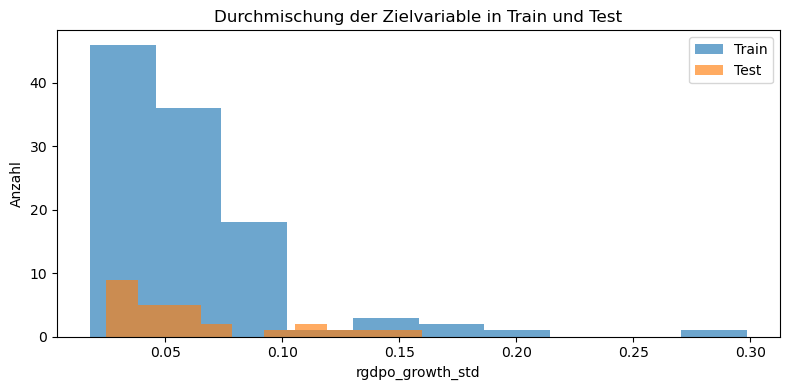

In [5]:
def make_balance_report(X_train, X_test, y_train, y_test):
    rows = []
    for col in X_train.select_dtypes(include=np.number).columns:
        pooled_sd = pd.concat([X_train[col], X_test[col]]).std(ddof=0)
        std_diff = np.nan if pooled_sd == 0 else (X_train[col].mean() - X_test[col].mean()) / pooled_sd
        rows.append({
            "variable": col,
            "train_mean": X_train[col].mean(),
            "test_mean": X_test[col].mean(),
            "abs_std_mean_diff": abs(std_diff),
        })
    y_pooled_sd = pd.concat([y_train, y_test]).std(ddof=0)
    rows.append({
        "variable": target_col,
        "train_mean": y_train.mean(),
        "test_mean": y_test.mean(),
        "abs_std_mean_diff": abs((y_train.mean() - y_test.mean()) / y_pooled_sd),
    })
    return pd.DataFrame(rows).sort_values("abs_std_mean_diff", ascending=False)

balance_report = make_balance_report(X_train, X_test, y_train, y_test)
display(balance_report)

split_bins = pd.DataFrame({
    "split": ["train" if idx in X_train.index else "test" for idx in X.index],
    "target_bin": strata,
})
bin_distribution = pd.crosstab(
    split_bins["target_bin"],
    split_bins["split"],
    normalize="columns",
).round(3)
print("Relative Verteilung der Ziel-Bins je Split:")
display(bin_distribution)

plt.figure(figsize=(8, 4))
plt.hist(y_train, bins=10, alpha=0.65, label="Train")
plt.hist(y_test, bins=10, alpha=0.65, label="Test")
plt.xlabel(target_col)
plt.ylabel("Anzahl")
plt.title("Durchmischung der Zielvariable in Train und Test")
plt.legend()
plt.tight_layout()
plt.show()

## 4. Cross-validation approach

Die Modelle werden nur auf dem Trainingsset per Cross-Validation verglichen. Das Testset bleibt bis zur finalen Bewertung unangetastet.

Verwendet wird **Repeated K-Fold Cross-Validation** mit 5 Folds und 3 Wiederholungen. Bei 135 Beobachtungen ist der Datensatz klein; wiederholte K-Fold-CV macht die Bewertung weniger abhängig von einer einzigen Fold-Aufteilung.

Quellen:  
- scikit-learn `RepeatedKFold`: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.RepeatedKFold.html  
- scikit-learn User Guide zu Cross-Validation: https://scikit-learn.org/stable/modules/cross_validation.html

In [6]:
cv = RepeatedKFold(
    n_splits=5,
    n_repeats=3,
    random_state=RANDOM_STATE,
)

scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2",
}

print(cv)
print("Scoring:", scoring)

RepeatedKFold(n_repeats=3, n_splits=5, random_state=42)
Scoring: {'MAE': 'neg_mean_absolute_error', 'RMSE': 'neg_root_mean_squared_error', 'R2': 'r2'}


## 5. Metrics

Für Regression werden diese Kennzahlen verwendet:

- **MAE** – durchschnittlicher absoluter Fehler; leicht interpretierbar in Einheiten der Zielvariable. Niedriger ist besser.  
- **RMSE** – bestraft größere Fehler stärker als MAE. Niedriger ist besser.  
- **R²** – erklärte Varianz; 1 ist ideal, 0 entspricht ungefähr einer Mittelwert-Baseline, negative Werte sind möglich.

Quellen:  
- scikit-learn Model Evaluation / Metrics: https://scikit-learn.org/stable/modules/model_evaluation.html  
- scikit-learn `mean_absolute_error`: https://scikit-learn.org/stable/modules/generated/sklearn.metrics.mean_absolute_error.html  
- scikit-learn `r2_score`: https://scikit-learn.org/stable/modules/generated/sklearn.metrics.r2_score.html

## 6. Performance results

Zuerst werden die Cross-Validation-Ergebnisse auf dem Trainingsset berechnet. Danach wird jedes Modell einmal auf dem gesamten Trainingsset fit gemacht und auf dem unabhängigen Testset ausgewertet.

In [7]:
cv_rows = []

for name, model in models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=1,
        return_train_score=False,
    )
    cv_rows.append({
        "model": name,
        "CV_MAE_mean": -scores["test_MAE"].mean(),
        "CV_MAE_sd": scores["test_MAE"].std(),
        "CV_RMSE_mean": -scores["test_RMSE"].mean(),
        "CV_RMSE_sd": scores["test_RMSE"].std(),
        "CV_R2_mean": scores["test_R2"].mean(),
        "CV_R2_sd": scores["test_R2"].std(),
    })

cv_results = (
    pd.DataFrame(cv_rows)
    .sort_values(["CV_RMSE_mean", "CV_MAE_mean"], ascending=[True, True])
    .reset_index(drop=True)
)

display(cv_results)

,model,CV_MAE_mean,CV_MAE_sd,CV_RMSE_mean,CV_RMSE_sd,CV_R2_mean,CV_R2_sd
0,Online Linear Regression (SGD),0.0255,0.0044,0.0375,0.0089,-0.0732,0.4694
1,Ridge Regression,0.0257,0.0044,0.0377,0.0088,-0.0841,0.4489
2,Random Forest,0.0266,0.0040,0.0390,0.0096,-0.1183,0.3459
3,Baseline: Mean,0.0267,0.0041,0.0394,0.0123,-0.0821,0.1978
4,Gradient Boosting,0.0274,0.0042,0.0405,0.0081,-0.3657,0.8994
5,Decision Tree,0.0309,0.0043,0.0451,0.0100,-0.5817,0.7283


In [8]:
fitted_models = {}
test_rows = []

for name, model in models.items():
    fitted = clone(model).fit(X_train, y_train)
    fitted_models[name] = fitted
    y_pred = fitted.predict(X_test)
    test_rows.append({
        "model": name,
        "Test_MAE": mean_absolute_error(y_test, y_pred),
        "Test_RMSE": root_mean_squared_error(y_test, y_pred),
        "Test_R2": r2_score(y_test, y_pred),
    })

test_results = (
    pd.DataFrame(test_rows)
    .sort_values(["Test_RMSE", "Test_MAE"], ascending=[True, True])
    .reset_index(drop=True)
)

display(test_results)

,model,Test_MAE,Test_RMSE,Test_R2
0,Decision Tree,0.0238,0.0292,0.3619
1,Online Linear Regression (SGD),0.0242,0.0299,0.3330
2,Ridge Regression,0.0241,0.0299,0.3314
3,Random Forest,0.0252,0.0302,0.3195
4,Gradient Boosting,0.0258,0.0326,0.2052
5,Baseline: Mean,0.0288,0.0366,-0.0000


## 7. Compare models

Die Modellwahl basiert primär auf dem mittleren Cross-Validation-RMSE. Das Testset dient anschließend als unabhängige Plausibilitätsprüfung der finalen Wahl.

,model,CV_MAE_mean,CV_MAE_sd,CV_RMSE_mean,CV_RMSE_sd,CV_R2_mean,CV_R2_sd,Test_MAE,Test_RMSE,Test_R2
0,Online Linear Regression (SGD),0.0255,0.0044,0.0375,0.0089,-0.0732,0.4694,0.0242,0.0299,0.3330
1,Ridge Regression,0.0257,0.0044,0.0377,0.0088,-0.0841,0.4489,0.0241,0.0299,0.3314
2,Random Forest,0.0266,0.0040,0.0390,0.0096,-0.1183,0.3459,0.0252,0.0302,0.3195
3,Baseline: Mean,0.0267,0.0041,0.0394,0.0123,-0.0821,0.1978,0.0288,0.0366,-0.0000
4,Gradient Boosting,0.0274,0.0042,0.0405,0.0081,-0.3657,0.8994,0.0258,0.0326,0.2052
5,Decision Tree,0.0309,0.0043,0.0451,0.0100,-0.5817,0.7283,0.0238,0.0292,0.3619


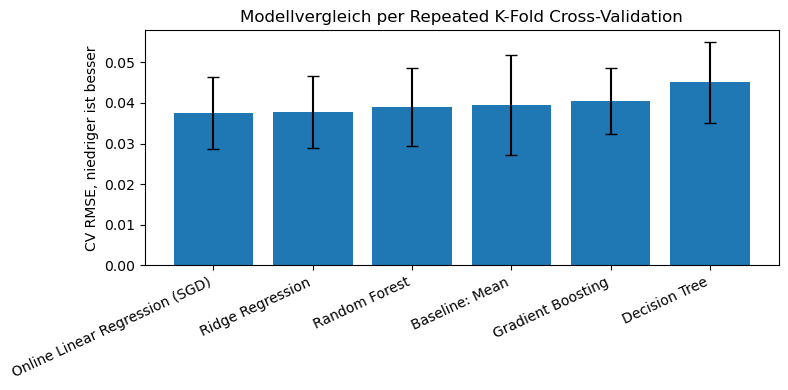

In [9]:
comparison = cv_results.merge(test_results, on="model", how="left")
display(comparison)

plot_df = cv_results.sort_values("CV_RMSE_mean", ascending=True)
plt.figure(figsize=(8, 4))
plt.bar(plot_df["model"], plot_df["CV_RMSE_mean"], yerr=plot_df["CV_RMSE_sd"], capsize=4)
plt.ylabel("CV RMSE, niedriger ist besser")
plt.title("Modellvergleich per Repeated K-Fold Cross-Validation")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

## 8. Select final model

Das finale Modell wird anhand des niedrigsten durchschnittlichen Cross-Validation-RMSE ausgewählt. Bei sehr ähnlichen RMSE-Werten sollten zusätzlich MAE, R², Modellstabilität und Interpretierbarkeit berücksichtigt werden.

In [10]:
final_model_name = cv_results.iloc[0]["model"]
final_model = fitted_models[final_model_name]

baseline_name = "Baseline: Mean"
final_cv = cv_results.loc[cv_results["model"] == final_model_name].iloc[0]
baseline_cv = cv_results.loc[cv_results["model"] == baseline_name].iloc[0]
final_test = test_results.loc[test_results["model"] == final_model_name].iloc[0]
baseline_test = test_results.loc[test_results["model"] == baseline_name].iloc[0]

rmse_improvement_cv = 100 * (baseline_cv["CV_RMSE_mean"] - final_cv["CV_RMSE_mean"]) / baseline_cv["CV_RMSE_mean"]
rmse_improvement_test = 100 * (baseline_test["Test_RMSE"] - final_test["Test_RMSE"]) / baseline_test["Test_RMSE"]

print(f"Finales Modell: {final_model_name}")
print(f"CV RMSE Verbesserung ggü. Baseline: {rmse_improvement_cv:.1f}%")
print(f"Test RMSE Verbesserung ggü. Baseline: {rmse_improvement_test:.1f}%")
print()
print("Begründung:")
print(
    f"Das Modell '{final_model_name}' hat den niedrigsten mittleren CV-RMSE "
    f"({final_cv['CV_RMSE_mean']:.3f}) unter den verglichenen Modellen. "
    f"Auf dem Testset erreicht es RMSE={final_test['Test_RMSE']:.3f}, "
    f"MAE={final_test['Test_MAE']:.3f}, R²={final_test['Test_R2']:.3f}."
)

# Optional: Für eine spätere produktive Nutzung kann nach der Evaluation auf allen Daten refittet werden.
final_model_all_data = clone(models[final_model_name]).fit(X, y)

Finales Modell: Online Linear Regression (SGD)
CV RMSE Verbesserung ggü. Baseline: 4.8%
Test RMSE Verbesserung ggü. Baseline: 18.3%

Begründung:
Das Modell 'Online Linear Regression (SGD)' hat den niedrigsten mittleren CV-RMSE (0.038) unter den verglichenen Modellen. Auf dem Testset erreicht es RMSE=0.030, MAE=0.024, R²=0.333.


### Quellen

- Die Baseline ist notwendig, weil `DummyRegressor` einfache Regeln nutzt und als Vergleichspunkt für echte Regressoren dient: https://scikit-learn.org/stable/modules/generated/sklearn.dummy.DummyRegressor.html  
- Ridge Regression löst ein Least-Squares-Regressionsproblem mit L2-Regularisierung: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html  
- `SGDRegressor` ist ein lineares Modell, das inkrementelles Lernen über `partial_fit` unterstützt und deshalb als online-fähige lineare Referenz passt: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.SGDRegressor.html  
- `DecisionTreeRegressor` dient als Batch-Baum-Vergleich zu Hoeffding-basierten Online-Bäumen: https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeRegressor.html  
- Random Forest mittelt viele Entscheidungsbäume, um Vorhersagegenauigkeit zu verbessern und Overfitting zu kontrollieren: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html  
- Gradient Boosting baut ein additives Modell schrittweise auf: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.GradientBoostingRegressor.html  
- Cross-Validation schätzt die Generalisierungsleistung über mehrere Aufteilungen: https://scikit-learn.org/stable/modules/cross_validation.html


## 9. Top features visualization

Zur Feature-Analyse wird **Permutation Importance** genutzt. Dabei wird jeweils ein Feature zufällig permutiert und gemessen, wie stark sich die Modellleistung verschlechtert. Das Verfahren ist modellagnostisch und daher auch für nichtlineare Modelle geeignet.

Quelle: scikit-learn `permutation_importance`: https://scikit-learn.org/stable/modules/generated/sklearn.inspection.permutation_importance.html

,feature,importance_RMSE_increase_mean,importance_RMSE_increase_sd
0,efotw_summary,0.0136,0.0039
1,efotw_world_bank_current_income_classification,0.0024,0.0015
2,efotw_standard_deviation_of_the_5_efw_areas,0.0020,0.0012
3,rgdpo,0.0006,0.0004
4,hdi_rank,0.0005,0.0008
5,Average_annual_HDI_growth_2010-2023,0.0003,0.0005
6,life_evaluation_(3-year_average),-0.0000,0.0003


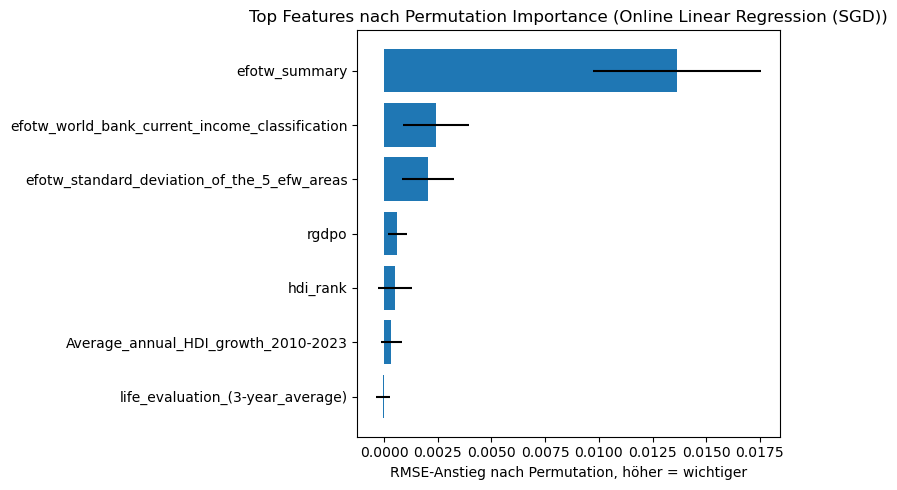

In [11]:
perm = permutation_importance(
    final_model,
    X_test,
    y_test,
    scoring="neg_root_mean_squared_error",
    n_repeats=30,
    random_state=RANDOM_STATE,
    n_jobs=1,
)

importance_df = pd.DataFrame({
    "feature": X_test.columns,
    "importance_RMSE_increase_mean": perm.importances_mean,
    "importance_RMSE_increase_sd": perm.importances_std,
}).sort_values("importance_RMSE_increase_mean", ascending=False).reset_index(drop=True)

display(importance_df)

top_n = min(10, len(importance_df))
plot_imp = importance_df.head(top_n).sort_values("importance_RMSE_increase_mean")
plt.figure(figsize=(8, 5))
plt.barh(plot_imp["feature"], plot_imp["importance_RMSE_increase_mean"], xerr=plot_imp["importance_RMSE_increase_sd"])
plt.xlabel("RMSE-Anstieg nach Permutation, höher = wichtiger")
plt.title(f"Top Features nach Permutation Importance ({final_model_name})")
plt.tight_layout()
plt.show()

## 10. Interpretation of feature impact

Permutation Importance zeigt die **Stärke** eines Merkmals, aber nicht direkt die **Richtung** des Effekts. Deshalb werden zusätzlich einfache modellagnostische Partial-Dependence-Kurven für die wichtigsten Features berechnet:

- positiver PDP-Effekt: höhere Feature-Werte erhöhen die vorhergesagte RGDPO-Wachstumsvolatilität.  
- negativer PDP-Effekt: höhere Feature-Werte senken die vorhergesagte RGDPO-Wachstumsvolatilität.  
- nahe 0: kein klarer durchschnittlicher Richtungseffekt.


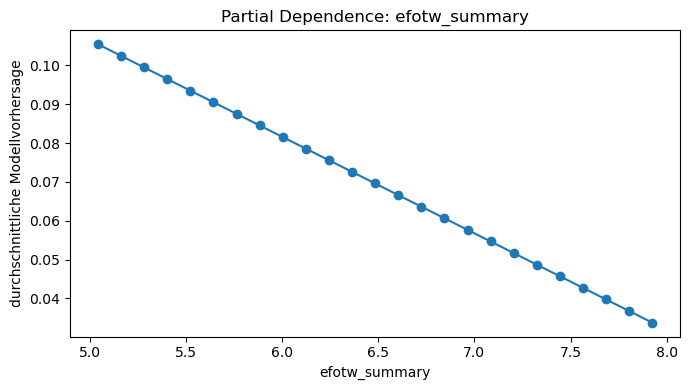

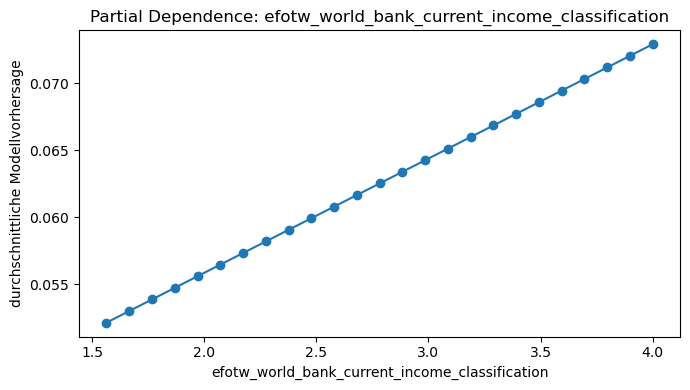

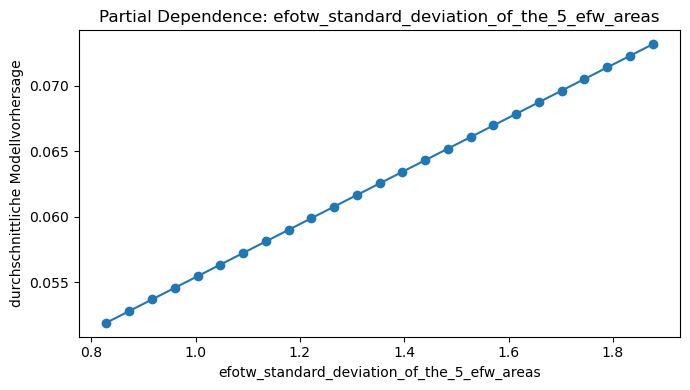

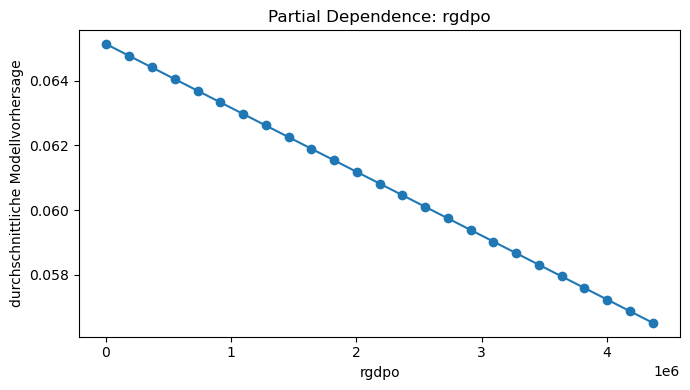

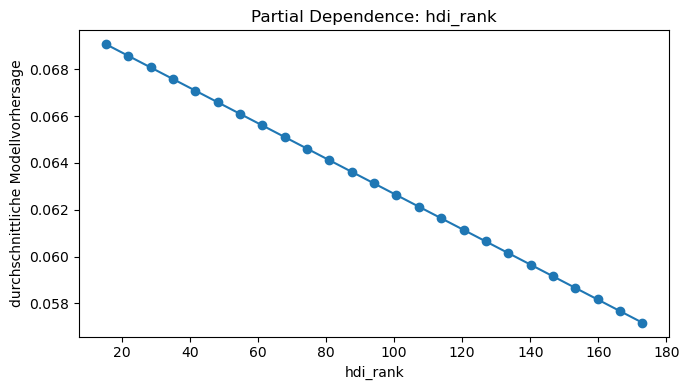

,feature,PDP_effect_high_minus_low,direction,low_grid_value,high_grid_value
0,efotw_summary,-0.0717,negativ,5.0422,7.9251
2,efotw_standard_deviation_of_the_5_efw_areas,0.0213,positiv,0.8290,1.8765
1,efotw_world_bank_current_income_classification,0.0208,positiv,1.5643,4.0000
4,hdi_rank,-0.0119,negativ,15.4000,172.9000
3,rgdpo,-0.0086,negativ,"5,332.7014","4,363,916.4411"


Interpretation der wichtigsten Features:
- efotw_summary: höhere Werte gehen im Modell mit einer niedrigeren vorhergesagten RGDPO-Wachstumsvolatilität einher (PDP high-low = -0.072).
- efotw_standard_deviation_of_the_5_efw_areas: höhere Werte gehen im Modell mit einer höheren vorhergesagten RGDPO-Wachstumsvolatilität einher (PDP high-low = 0.021).
- efotw_world_bank_current_income_classification: höhere Werte gehen im Modell mit einer höheren vorhergesagten RGDPO-Wachstumsvolatilität einher (PDP high-low = 0.021).
- hdi_rank: höhere Werte gehen im Modell mit einer niedrigeren vorhergesagten RGDPO-Wachstumsvolatilität einher (PDP high-low = -0.012).
- rgdpo: höhere Werte gehen im Modell mit einer niedrigeren vorhergesagten RGDPO-Wachstumsvolatilität einher (PDP high-low = -0.009).


In [12]:
def partial_dependence_manual(model, X_reference, feature, grid_points=25):
    """Einfache modellagnostische PDP-Berechnung für numerische Features."""
    feature_values = X_reference[feature].dropna()
    if feature_values.nunique() < 2:
        return pd.DataFrame(columns=[feature, "mean_prediction"])
    low, high = feature_values.quantile([0.05, 0.95])
    grid = np.linspace(low, high, grid_points)
    preds = []
    for value in grid:
        X_temp = X_reference.copy()
        X_temp[feature] = value
        preds.append(model.predict(X_temp).mean())
    return pd.DataFrame({feature: grid, "mean_prediction": preds})

top_features = importance_df.query("importance_RMSE_increase_mean > 0").head(5)["feature"].tolist()
if not top_features:
    top_features = importance_df.head(5)["feature"].tolist()

pdp_summaries = []

for feature in top_features:
    if feature not in numeric_features:
        continue
    curve = partial_dependence_manual(final_model, X_test, feature)
    if curve.empty:
        continue
    effect = curve["mean_prediction"].iloc[-1] - curve["mean_prediction"].iloc[0]
    # Dynamische Schwelle, weil `rgdpo_growth_std` typischerweise kleine Dezimalwerte hat.
    effect_threshold = max(0.05 * y_test.std(), 1e-6)
    if effect > effect_threshold:
        direction = "positiv"
    elif effect < -effect_threshold:
        direction = "negativ"
    else:
        direction = "nahezu neutral"
    pdp_summaries.append({
        "feature": feature,
        "PDP_effect_high_minus_low": effect,
        "direction": direction,
        "low_grid_value": curve[feature].iloc[0],
        "high_grid_value": curve[feature].iloc[-1],
    })
    
    plt.figure(figsize=(7, 4))
    plt.plot(curve[feature], curve["mean_prediction"], marker="o")
    plt.xlabel(feature)
    plt.ylabel("durchschnittliche Modellvorhersage")
    plt.title(f"Partial Dependence: {feature}")
    plt.tight_layout()
    plt.show()

pdp_summary_df = pd.DataFrame(pdp_summaries).sort_values(
    "PDP_effect_high_minus_low", key=lambda s: s.abs(), ascending=False
)
display(pdp_summary_df)

print("Interpretation der wichtigsten Features:")
for _, row in pdp_summary_df.iterrows():
    effect = row["PDP_effect_high_minus_low"]
    feature = row["feature"]
    direction = row["direction"]
    if direction == "positiv":
        text = "höhere Werte gehen im Modell mit einer höheren vorhergesagten RGDPO-Wachstumsvolatilität einher"
    elif direction == "negativ":
        text = "höhere Werte gehen im Modell mit einer niedrigeren vorhergesagten RGDPO-Wachstumsvolatilität einher"
    else:
        text = "der durchschnittliche Richtungseffekt ist im Modell schwach oder uneindeutig"
    print(f"- {feature}: {text} (PDP high-low = {effect:.3f}).")

## Fazit

Dieses Notebook deckt die geforderten Folienpunkte ab und wurde um die für dieses Regressionsproblem relevanten Online-Machine-Learning-Modelle erweitert:

- Baseline model  
- Additional ML models  
- relevante OML-Regression: Online Linear Regression, Hoeffding Tree Regressor, Hoeffding Adaptive Tree Regressor, Adaptive Random Forest Regressor, sofern `river` verfügbar ist  
- Why these methods? Sources  
- Train-test split mit sehr guter Durchmischung  
- Cross-validation approach  
- Metrics  
- Performance results  
- Compare models  
- Select final model  
- Justification Sources  
- Top features visualization  
- Interpretation of feature impact

Wichtig: Der aktuelle Split mischt Länderbeobachtungen bewusst stark durch. Für eine echte Online-/Stream-Evaluation sollte zusätzlich eine zeitlich oder prozessual sinnvolle Reihenfolge definiert werden und dann eine Prequential- bzw. Walk-forward-Evaluation ergänzt werden.
